# Setup imports and paths

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path


# Input dataset if in root dir 
SOURCE = Path("../data/hour.csv")

# Dir for reluts
OUTPUT = Path("../results/python")

print("Current working folder:", Path.cwd())

if not SOURCE.exists():
    raise FileNotFoundError("Cannot find data/hour.csv. Check your working folder and file location.")

OUTPUT.mkdir(parents=True, exist_ok=True)  # Create out dir if it does not exist

print("Reading:", SOURCE)
print("Saving results in:", OUTPUT)

Current working folder: c:\Users\Acer NITRO\Desktop\projects\Same-analysis-4-technologies\python
Reading: ..\data\hour.csv
Saving results in: ..\results\python


# Read and inspect
- df.head() for the first five rows.
- df.head() for the first five rows.
- df.shape return tuple (number of rows, number of columns).
- df.info() summary of column names and data types.
- df.isna().sum() for missing values per column (True counts as 1).

In [9]:
df = pd.read_csv(SOURCE)

display(df.head())
print("Rows and columns:", df.shape)

df.info()
print("Missing values per column:")

print(df.isna().sum())

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


Rows and columns: (17379, 17)
<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.3 MB
Missing values per column:
instant

# Check source data
##### These checks tell whether we loaded the original UCI hour.csv:
1. It should have 17,379 recorded-hour rows.
2. Sum of cnt should be 3,292,679 rentals.
3. Each row should satisfy cnt = casual + registered.
4. No two rows should describe the same date and hour.

In [10]:
print("Rows:", len(df))
print("Total rentals:", df["cnt"].sum())

# Count rows where the rental totals do not match
wrong_counts = (df["cnt"] != df["casual"] + df["registered"]).sum()

# Count repeated combinations of date + hour
duplicate_hours = df.duplicated(subset=["dteday", "hr"]).sum()

print("Rows with incorrect rental totals:", wrong_counts)
print("Duplicate date/hour rows:", duplicate_hours)

# assert -> if the condition is false, stop and show an error
assert len(df) == 17_379
assert df["cnt"].sum() == 3_292_679
assert wrong_counts == 0
assert duplicate_hours == 0
print("All four checks passed.")

Rows: 17379
Total rentals: 3292679
Rows with incorrect rental totals: 0
Duplicate date/hour rows: 0
All four checks passed.


# Prepare the date for monthly analysis
The column dteday initially has dates read from the CSV → convert it into a proper pandas date, then create a year_month label such as 2011-01.

*Why? If we grouped by mnth alone, January 2011 and January 2012 would be combined. The YYYY-MM label keeps them separate and sorts chronologically.*
- pd.to_datetime(...) -  convert text to dates.
- df["dteday"].dt - access date components for the entire date column.
- .strftime("%Y-%m") - format each date as four-digit year–two-digit month.

In [ ]:
df["dteday"] = pd.to_datetime(df["dteday"], format="%Y-%m-%d")
df["year_month"] = df["dteday"].dt.strftime("%Y-%m")

#check
display(df[["dteday", "year_month", "hr", "cnt"]].head())

,dteday,year_month,hr,cnt
0,2011-01-01,2011-01,0,16
1,2011-01-01,2011-01,1,40
2,2011-01-01,2011-01,2,32
3,2011-01-01,2011-01,3,13
4,2011-01-01,2011-01,4,1


# Calculate the results
## Two overall metrics
- .sum() adds the number of rentals in all recorded hours.
- .mean() computes the average rentals per recorded hour.
We store the two results in a tiny two-column summary table because later we want to export the same table from R, Excel and Power BI.


In [12]:
total_rentals = df["cnt"].sum()
avg_hourly_demand = df["cnt"].mean()

summary = pd.DataFrame({
    "metric": ["total_rentals", "avg_hourly_demand"],
    "value": [total_rentals, avg_hourly_demand],
})
display(summary)

,metric,value
0,total_rentals,3.292679e+06
1,avg_hourly_demand,1.894631e+02


## Grouped metrics
We compute four grouped tables:
| Table | Group by | Calculation | Output columns |
|---|---|---|---|
| `hourly` | `hr` | mean `cnt` | `hr`, `avg_rentals` |
| `workingday` | `workingday` | mean `cnt` | `workingday`, `avg_rentals` |
| `weather` | `weathersit` | mean `cnt` | `weathersit`, `avg_rentals` |
| `monthly` | `year_month` | sum `cnt` | `year_month`, `total_rentals` |

*how:*
operations execute from left to right (1st line example):
1. df.groupby("hr"): Splits the dataset into separate buckets for each unique hour of the day (0 through 23).
2. ["cnt"]: Focuses only on the "cnt" column (total bike rentals) inside each hour bucket, ignoring all other columns.
3. .mean(): Calculates the average number of rentals for each hour. At this point, pandas produces a Series where "hr" is the index, not a regular column.
4. .reset_index(name="avg_rentals"): Converts that Series back into a standard DataFrame with two regular columns:
   1. "hr" (moved out of the index)
   2. "avg_rentals" (the calculated averages, renamed from "cnt")


In [13]:
hourly = df.groupby("hr")["cnt"].mean().reset_index(name="avg_rentals")
workingday = df.groupby("workingday")["cnt"].mean().reset_index(name="avg_rentals")
weather = df.groupby("weathersit")["cnt"].mean().reset_index(name="avg_rentals")
monthly = df.groupby("year_month")["cnt"].sum().reset_index(name="total_rentals")

print("AVERAGE BY HOUR")
display(hourly)
print("AVERAGE BY WORKING-DAY STATUS")
display(workingday)
print("AVERAGE BY WEATHER")
display(weather)
print("MONTHLY TOTALS")
display(monthly)

AVERAGE BY HOUR


,hr,avg_rentals
0,0,53.898072
1,1,33.375691
2,2,22.869930
3,3,11.727403
4,4,6.352941
5,5,19.889819
6,6,76.044138
7,7,212.064649
8,8,359.011004
9,9,219.309491


AVERAGE BY WORKING-DAY STATUS


,workingday,avg_rentals
0,0,181.405332
1,1,193.207754


AVERAGE BY WEATHER


,weathersit,avg_rentals
0,1,204.869272
1,2,175.165493
2,3,111.579281
3,4,74.333333


MONTHLY TOTALS


,year_month,total_rentals
0,2011-01,38189
1,2011-02,48215
2,2011-03,64045
3,2011-04,94870
4,2011-05,135821
5,2011-06,143512
6,2011-07,141341
7,2011-08,136691
8,2011-09,127418
9,2011-10,123511


# Quick check + one result
*Summing the 24 monthly totals should give the same figure as summing all cnt values directly.*

idxmax() finds the row index containing the largest value; .loc[...] then selects the corresponding hour → lets us identify the peak-average-demand hour.

In [14]:
assert monthly["total_rentals"].sum() == total_rentals

peak_index = hourly["avg_rentals"].idxmax()
peak_hour = hourly.loc[peak_index, "hr"]
peak_average = hourly.loc[peak_index, "avg_rentals"]

print(f"Peak average-demand hour: {peak_hour:02.0f}:00")
print(f"Average rentals at that hour: {peak_average:.2f}")
print(f"Overall average per observed hour: {avg_hourly_demand:.2f}")

Peak average-demand hour: 17:00
Average rentals at that hour: 461.45
Overall average per observed hour: 189.46


# Make three charts
Each chart is shown in the notebook and saved as a PNG file:
- plt.plot(x, y) draws a line chart.
- plt.bar(x, y) draws a bar chart.
- plt.xlabel, plt.ylabel, plt.title set labels.
- plt.tight_layout() adjusts spacing.
- plt.savefig(...) saves the chart; plt.show() displays it.
! Cross check that metric definitions match across all technologies

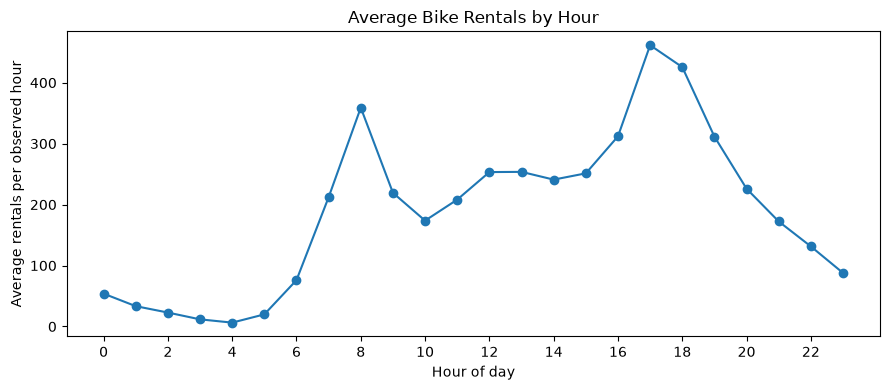

In [15]:

# 1: Average rentals by hour (0–23)

plt.figure(figsize=(9, 4))
plt.plot(hourly["hr"], hourly["avg_rentals"], marker="o")
plt.title("Average Bike Rentals by Hour")
plt.xlabel("Hour of day")
plt.ylabel("Average rentals per observed hour")
plt.xticks(range(0, 24, 2))
plt.tight_layout()

plt.savefig(OUTPUT / "chart_hourly.png")
plt.show()

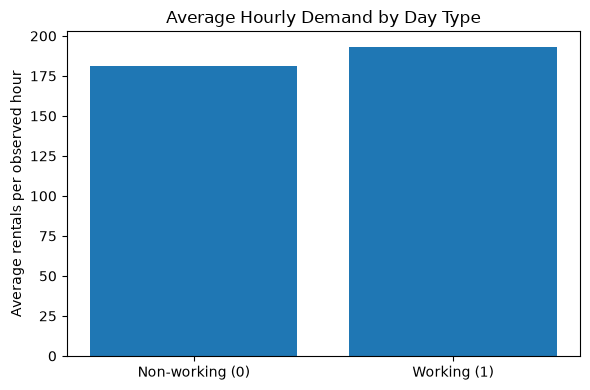

In [16]:
# Chart 2: Average demand on working vs non-working days

plt.figure(figsize=(6, 4))
plt.bar(["Non-working (0)", "Working (1)"], workingday["avg_rentals"])
plt.title("Average Hourly Demand by Day Type")

plt.ylabel("Average rentals per observed hour")
plt.tight_layout()

plt.savefig(OUTPUT / "chart_workingday.png")
plt.show()

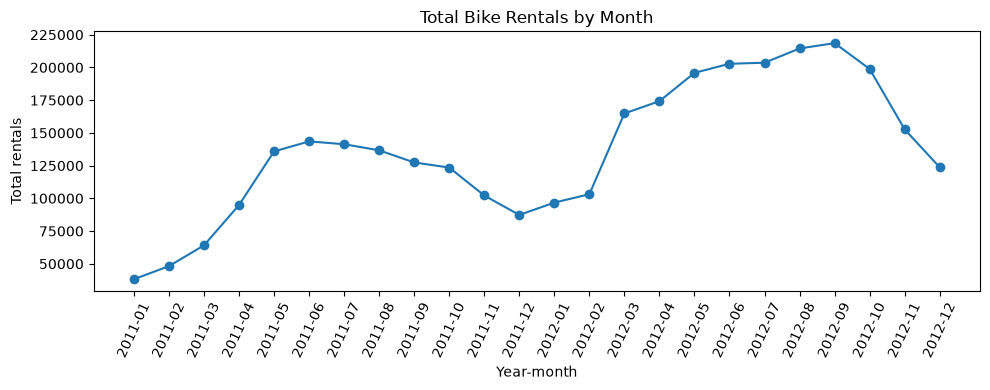

In [17]:
# Chart 3: Monthly total rentals (2011–2012)

plt.figure(figsize=(10, 4))
plt.plot(monthly["year_month"], monthly["total_rentals"], marker="o")
plt.title("Total Bike Rentals by Month")
plt.xlabel("Year-month")
plt.ylabel("Total rentals")
plt.xticks(rotation=65)
plt.tight_layout()

plt.savefig(OUTPUT / "chart_monthly.png")
plt.show()

# Export the five result tables

- .to_csv(path, index=False) writes a DataFrame to a CSV without an extra unnamed row-index column.
- We export raw numeric values rather than intentionally rounding them for presentation

! The three PNG files have already been saved by the chart cells above 


In [18]:
summary.to_csv(OUTPUT / "summary.csv", index=False)
hourly.to_csv(OUTPUT / "hourly.csv", index=False)
workingday.to_csv(OUTPUT / "workingday.csv", index=False)
weather.to_csv(OUTPUT / "weather.csv", index=False)
monthly.to_csv(OUTPUT / "monthly.csv", index=False)

print("Saved 5 result tables to:", OUTPUT)

Saved 5 result tables to: ..\results\python


### sanity check if files were saved successfully

In [19]:
saved_hourly = pd.read_csv(OUTPUT / "hourly.csv")
assert len(saved_hourly) == 24
print("Phase 1 complete. Exported files:")
for file in sorted(OUTPUT.iterdir()):
    print(" -", file.name)

Phase 1 complete. Exported files:
 - chart_hourly.png
 - chart_monthly.png
 - chart_workingday.png
 - hourly.csv
 - monthly.csv
 - summary.csv
 - weather.csv
 - workingday.csv
